# The Rain Timetable

Two years can receive similar rainfall totals while experiencing different sequences of wet and dry days. I examine how those sequences relate to regional satellite greenness in the southern Great Plains.


In [1]:
from pathlib import Path
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    raise RuntimeError("Open this notebook from the repository directory.")
sys.path.insert(0, str(ROOT / "src"))
from download import download_data
from analysis import *
for folder in ["data/processed", "outputs/figures", "outputs/tables"]:
    (ROOT / folder).mkdir(parents=True, exist_ok=True)

In [2]:
downloads = download_data(ROOT, refresh=False)
print("Dataset revision:", "18f4efa2a0fcab0a2bd74203896e8c21d9f95ebb")
print(downloads[["file", "bytes", "rows", "http_status", "access"]].to_string(index=False))

Dataset revision: 18f4efa2a0fcab0a2bd74203896e8c21d9f95ebb
                                             file   bytes   rows  http_status access
     GreatPlains_CHIRPS_DailyPrecip_2000_2024.csv  781263 9131.0          200 cached
      GreatPlains_MOD09A1_NDVI_8day_2000_2024.csv  101064 1143.0          200 cached
GreatPlains_ERA5L_SoilTempPET_Daily_2000_2024.csv 1159675 9131.0          200 cached
                                        README.md    8134    NaN          200 cached


The following cell checks column names, dates, missing values, numerical ranges, and daily coverage. 
Check and process missing values. I use complete calendar years from 2001 onward.  Missing NDVI observations are dropped.

,source,rows,start,end,missing_values,duplicate_dates,absent_dates
0,CHIRPS,9131,2000-01-01,2024-12-30,0,0,0
1,MODIS NDVI,1143,2000-02-18,2024-12-26,2,0,1
2,ERA5-Land,9131,2000-01-01,2024-12-30,0,0,0


Retained complete years: 2001 to 2023
Retained daily rows: 8400 | Retained NDVI observations: 1055


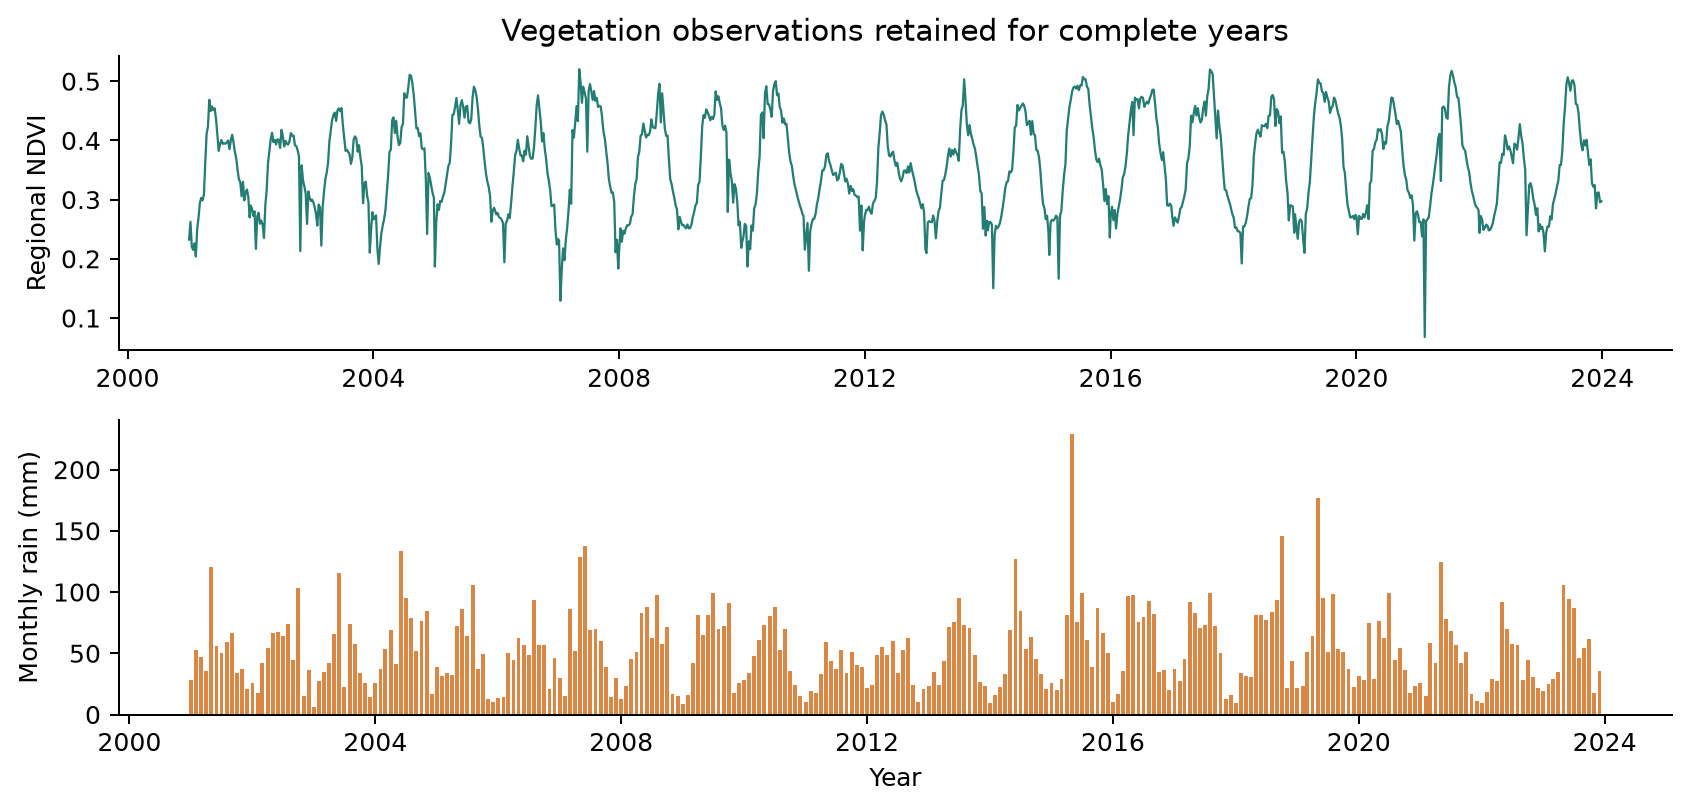

In [3]:
daily, vegetation, audit = load_validate(ROOT)
display(audit)
print("Retained complete years:", daily.index.year.min(), "to", daily.index.year.max())
print("Retained daily rows:", len(daily), "| Retained NDVI observations:", len(vegetation))
plot_overview(ROOT, daily, vegetation)

seasonal cycle
 
The shaded bands:  the 10th to 90th percentiles across available observations. 

I focus on April through September for comparisons; this fixed window makes each year comparable without estimating a separate growing season from its NDVI.

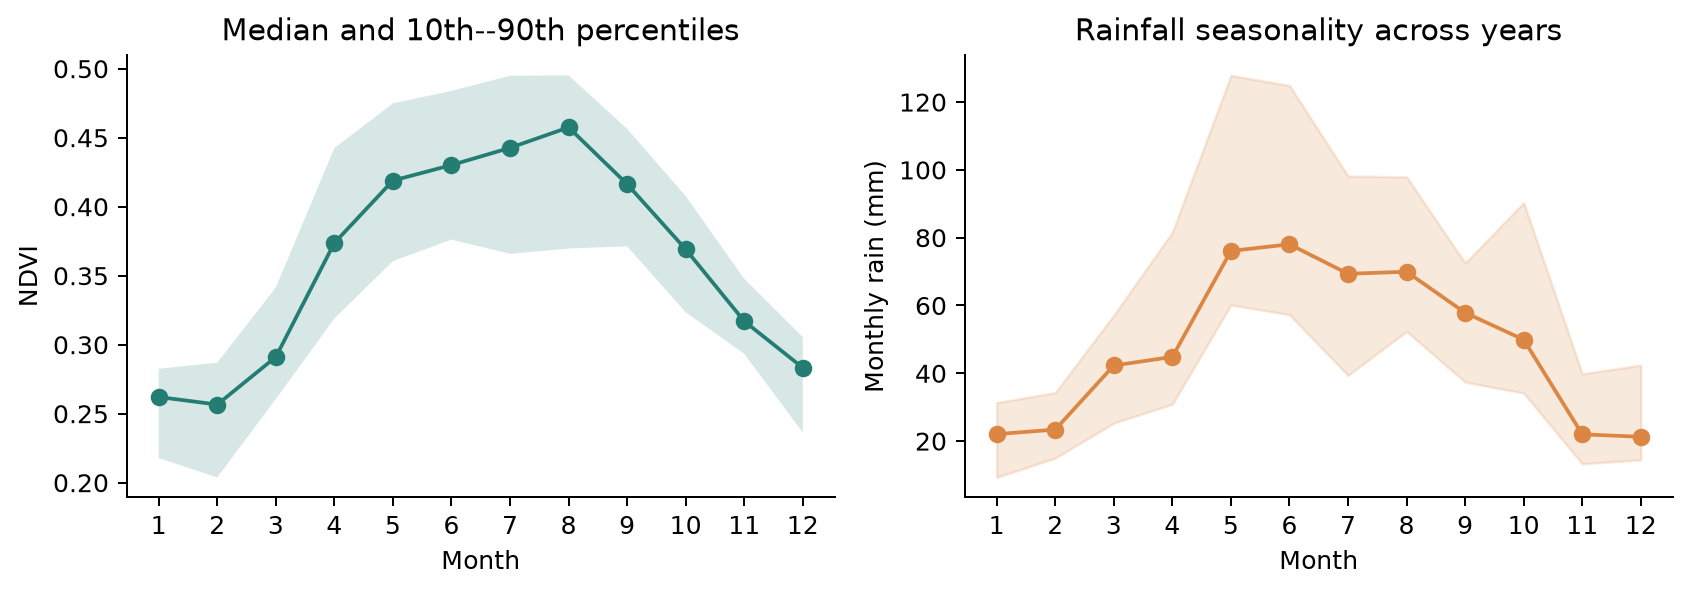

Annual rainfall range (mm): 437.2 864.0
Seasonal mean NDVI range: 0.345 0.463


In [4]:
plot_seasonal(ROOT, daily, vegetation)
annual = annual_summary(ROOT, daily, vegetation)
print("Annual rainfall range (mm):", annual.annual_rain.min().round(1), annual.annual_rain.max().round(1))
print("Seasonal mean NDVI range:", annual.ndvi_mean.min().round(3), annual.ndvi_mean.max().round(3))

The following cell measures rain concentration as the sum of squared daily rainfall shares. A larger value means that fewer days carry more of the seasonal rainfall. A wet day has at least 1 mm of regional mean rain. I compare every pair of years whose annual totals differ by at most 10% of their average.

Eligible pairs: 85


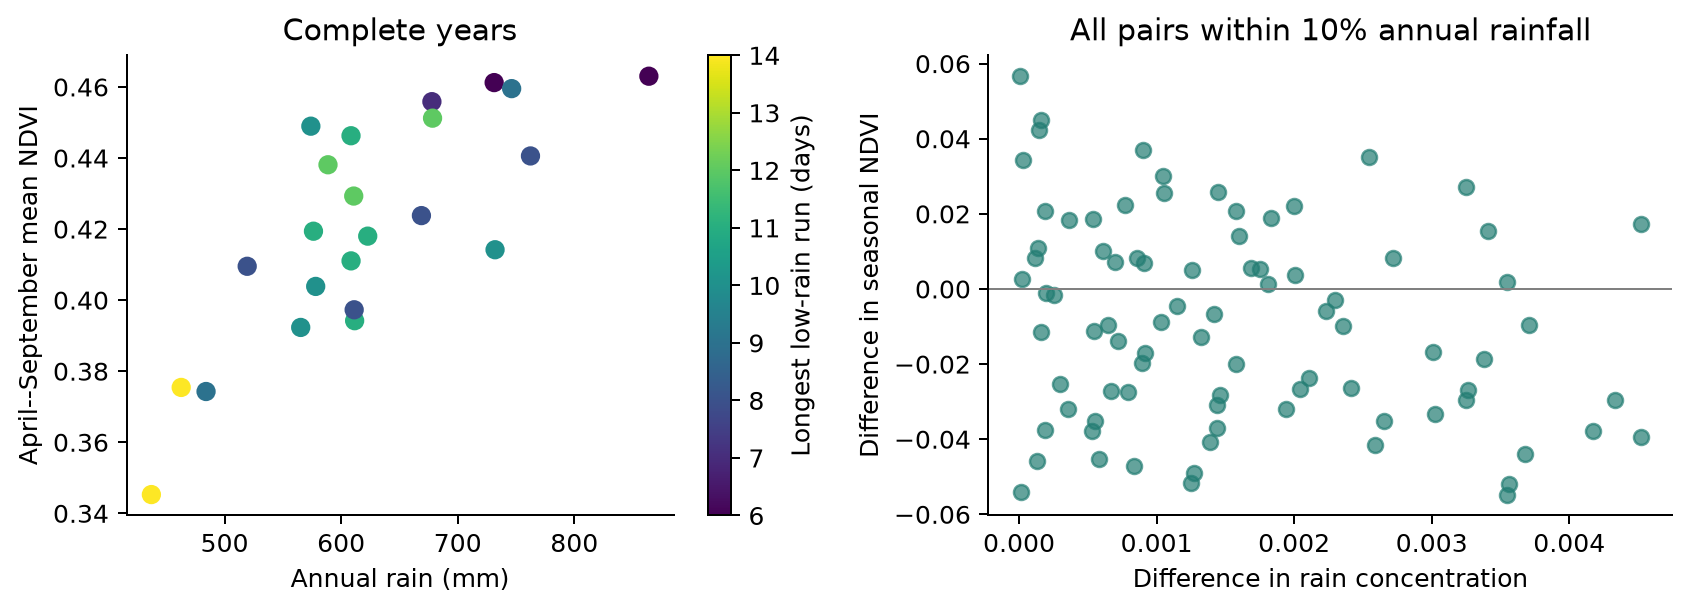

,year,annual_rain,rain_total,wet_days,dry_run,concentration,top10_share,ndvi_mean
2,2003,519.3876,377.9319,89,8,0.0188,0.4933,0.4095
5,2006,565.2936,363.5107,95,10,0.0143,0.4195,0.3923


In [5]:
pairs = match_years(annual, tolerance=0.10)
table(ROOT, "matched_pairs", pairs)
print("Eligible pairs:", len(pairs))
plot_annual(ROOT, annual, pairs)
pair = choose_pair(pairs)
years = [int(pair.year_low), int(pair.year_high)]
pair_details = annual.loc[annual.year.isin(years),
    ["year", "annual_rain", "rain_total", "wet_days", "dry_run", "concentration", "top10_share", "ndvi_mean"]]
table(ROOT, "illustrated_pair", pair_details)
display(pair_details.round(4))

The eligible pair with the largest difference in seasonal rain concentration. 
The selection uses rainfall alone. Gray bands mark each year's longest April--September run below 1 mm/day.

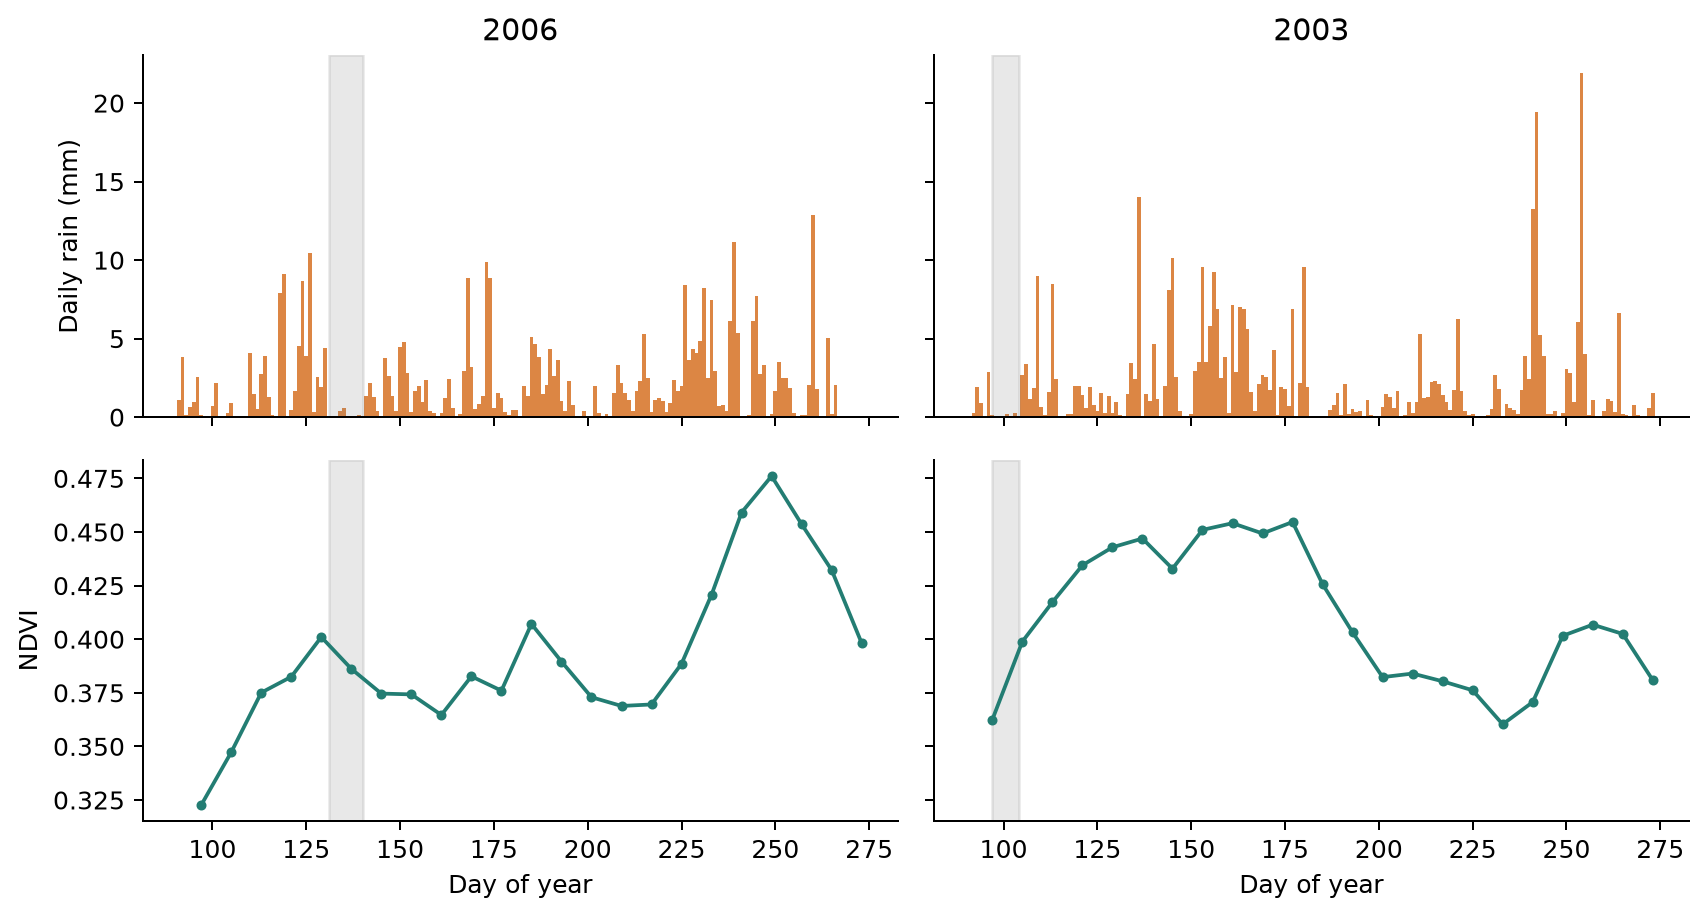

In [6]:
plot_pair(ROOT, daily, vegetation, pair)

The longest low-rain spell in each year. 
Reference :the last NDVI composite ending before the spell.

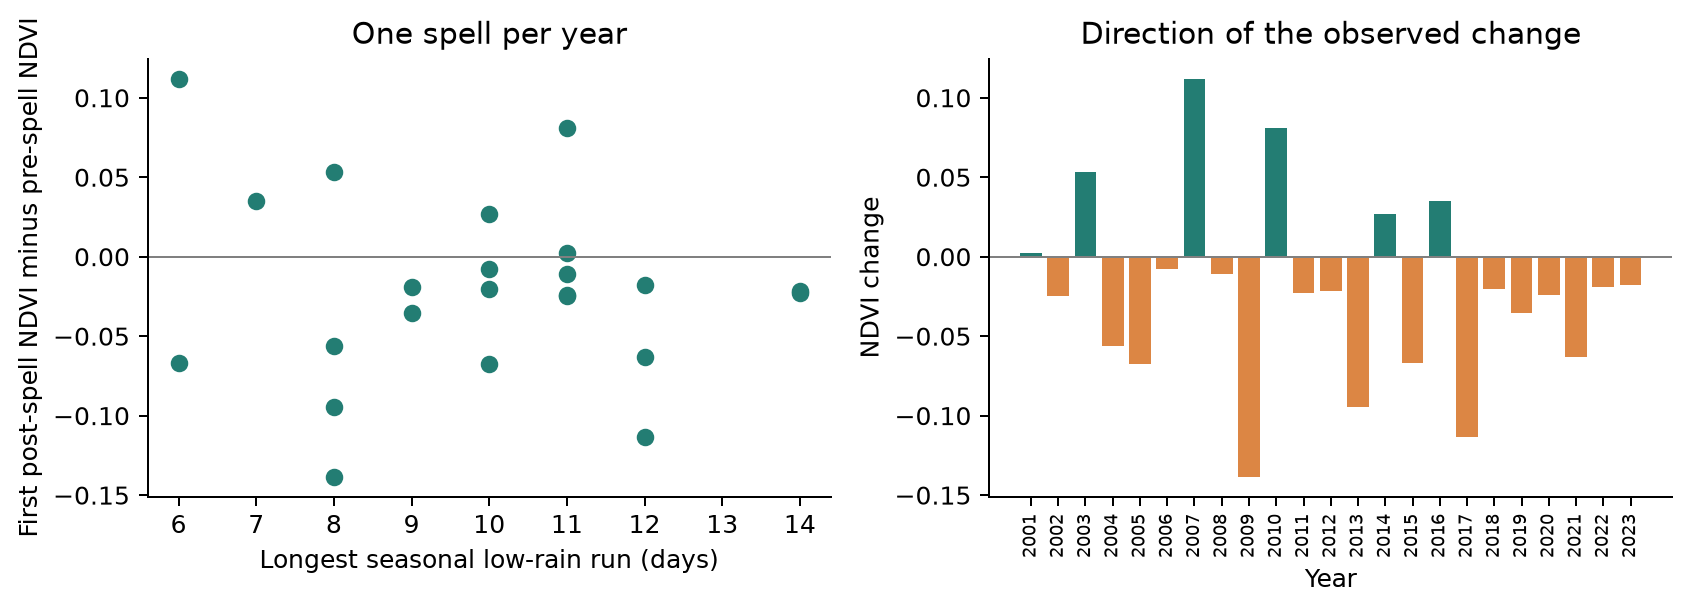

,Measure,Value
0,Spells with reference and follow-up,23.0
1,Negative NDVI changes,17.0
2,Observed recoveries after a decline,2.0
3,Median spell length (days),10.0
4,Maximum spell length (days),14.0


In [7]:
events = spell_responses(ROOT, daily, vegetation)
event_summary = pd.DataFrame({"Measure": ["Spells with reference and follow-up", "Negative NDVI changes", "Observed recoveries after a decline", "Median spell length (days)", "Maximum spell length (days)"],
    "Value": [len(events), int(events.decline.sum()), int(events.recovery_observed.sum()), events.days.median(), events.days.max()]})
table(ROOT, "event_summary", event_summary)
display(event_summary)

Features: extracted from the 32 days strictly before each NDVI composite starts. 

Each test year from 2010 onward is predicted using earlier years only. Feature scaling is fitted to the training years. 

,model,n,mae,rmse,r2
0,Amount + prior NDVI,322,0.01503,0.01958,0.86412
1,Persistence,322,0.01582,0.02164,0.83402
2,Rain amount,322,0.03250,0.03917,0.45619
3,Rain timing,322,0.03090,0.03815,0.48414
4,Season + temperature,322,0.04139,0.04955,0.12977
5,Timing + prior NDVI,322,0.01490,0.01946,0.86586


Prediction rows: 528 | Held-out years: 14


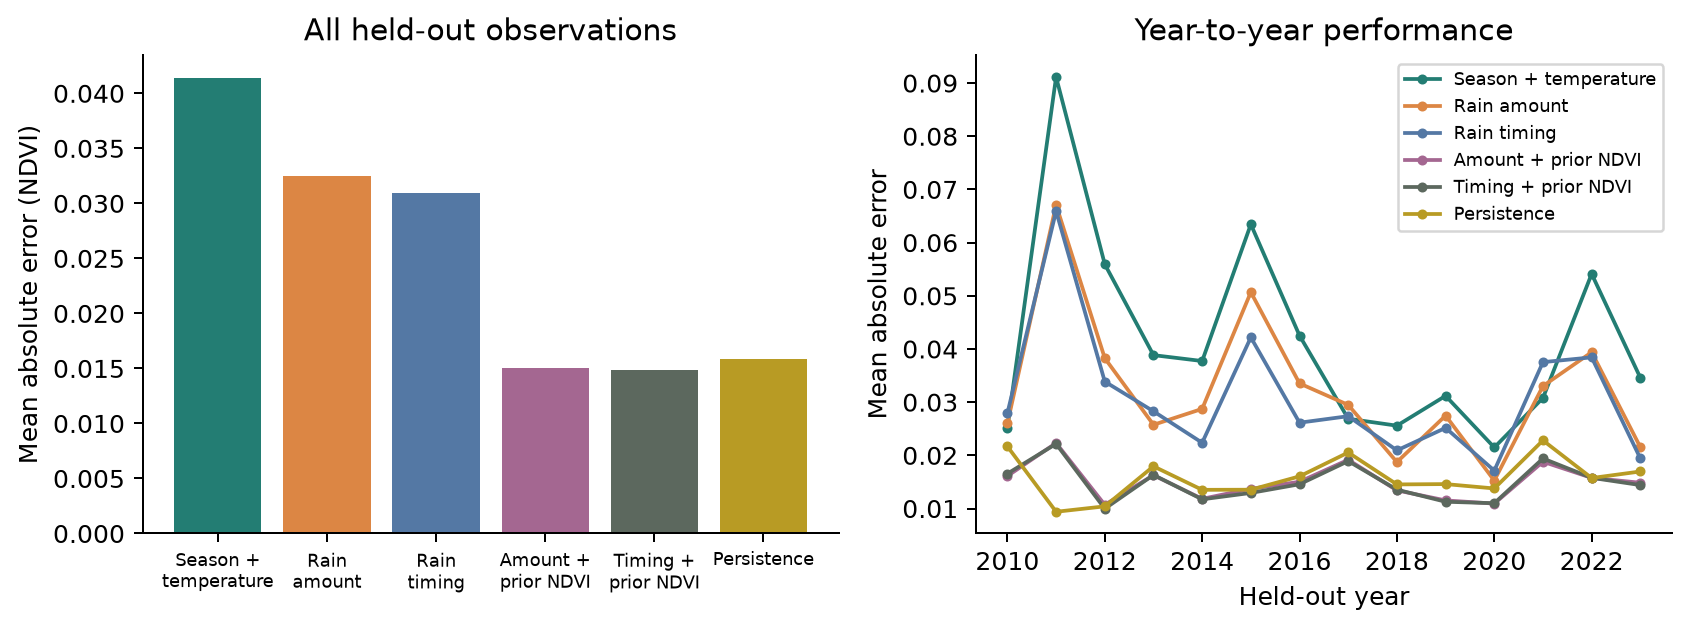

In [8]:
features = feature_frame(daily, vegetation, window=32, threshold=1.0)
assert (features.feature_last_date < features.date).all()
features.to_csv(ROOT / "data/processed/prediction_features.csv", index=False)
predictions, folds, scores = evaluate(features)
table(ROOT, "predictions", predictions)
table(ROOT, "yearly_errors", folds)
table(ROOT, "model_scores", scores)
display(scores.round(5))
print("Prediction rows:", len(features), "| Held-out years:", folds.year.nunique())
plot_evaluation(ROOT, predictions, folds, scores)

Check whether the comparison depends on the antecedent window or the wet-day threshold.

 The left panel reports the change in prediction error when timing features are added. Positive values favor the timing model. The right panel shows how many year pairs satisfy different annual-total matching tolerances.

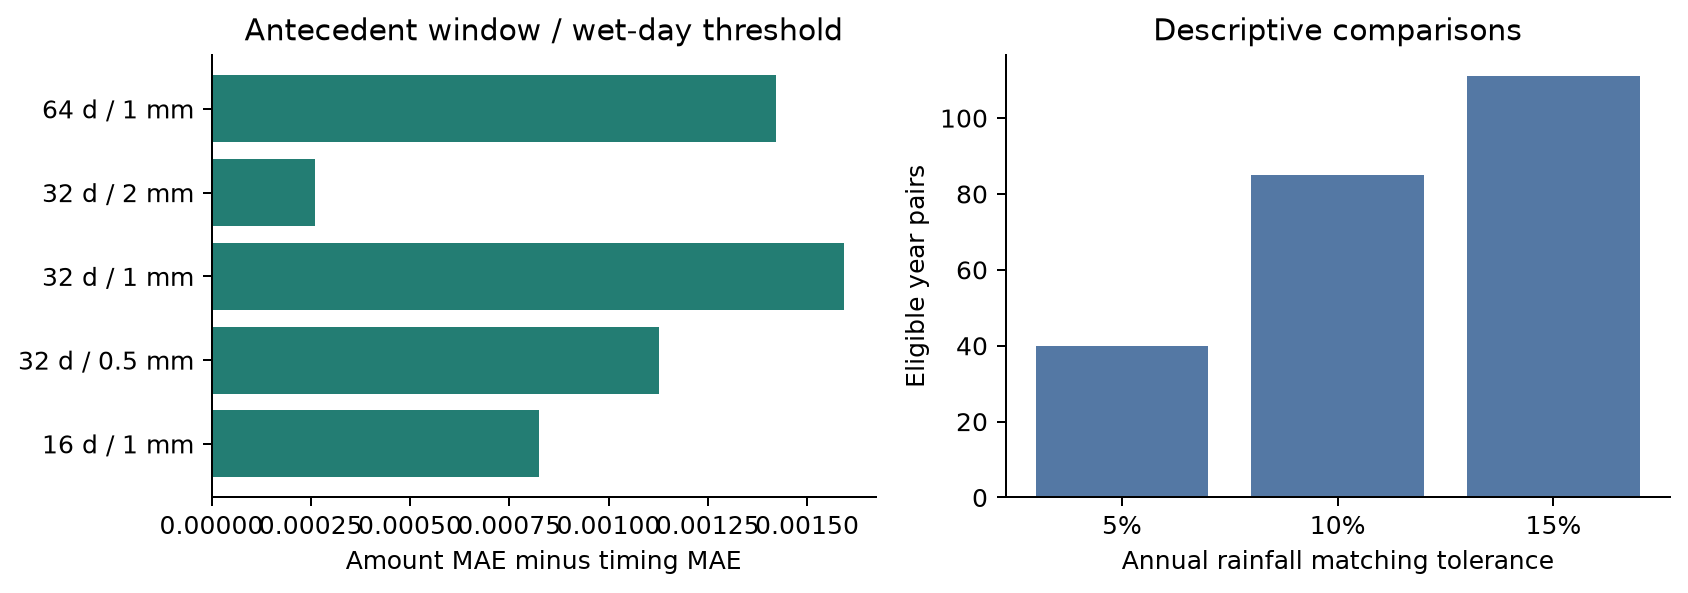

,window,threshold,n,amount_mae,timing_mae,improvement
0,16,1.0,322,0.03578,0.03496,0.00082
1,32,0.5,322,0.03250,0.03137,0.00113
2,32,1.0,322,0.03250,0.03090,0.00159
3,32,2.0,322,0.03250,0.03224,0.00026
4,64,1.0,322,0.02855,0.02713,0.00142


In [9]:
sensitivity_results, matching_counts = sensitivity(ROOT, daily, vegetation, annual)
display(sensitivity_results.round(5))

In [10]:
results = summary(ROOT, annual, pairs, pair, events, features, scores, folds, sensitivity_results)
print("Years with smaller error after adding timing:", results["improved_years"], "/", results["test_years"])
print("Mean annual MAE improvement:", round(results["mean_year_mae_improvement"], 5))
print("Year-bootstrap 95% interval:", [round(x, 5) for x in results["improvement_interval"]])
print("Settings with smaller timing-model error:", results["sensitivity_positive"], "/", len(sensitivity_results))

Years with smaller error after adding timing: 9 / 14
Mean annual MAE improvement: 0.00159
Year-bootstrap 95% interval: [-0.00035, 0.00358]
Settings with smaller timing-model error: 5 / 5
